(53940, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


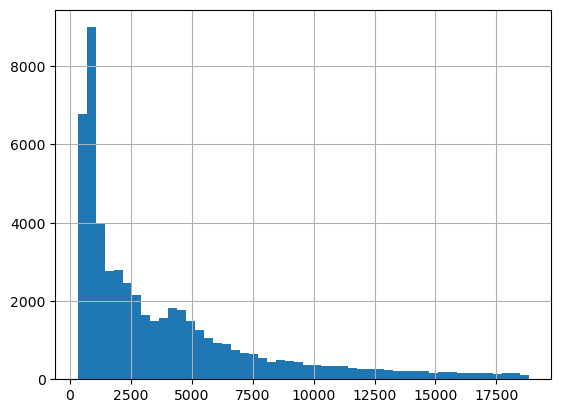

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\hp\OneDrive\Documents\shameel\data\diamon.txt")        
print(df.shape)
df.info()
df.describe()
df["price"].hist(bins=50); plt.show()  

In [3]:
print((df[["x","y","z"]] == 0).sum())
df = df.drop_duplicates()
df = df[(df[["x","y","z"]] > 0).all(axis=1)]
df = df[(df["y"] < 20) & (df["z"] < 20)]
print(df.shape)                        

x     8
y     7
z    20
dtype: int64
(53772, 10)


In [4]:
df["log_carat"] = np.log(df["carat"])
y = np.log(df["price"])

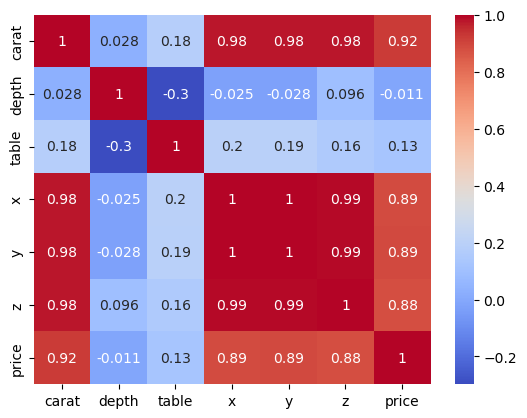

In [5]:
num_cols = ["carat","depth","table","x","y","z","price"]
import seaborn as sns
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm"); plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression

cats = ["cut","color","clarity"]
nums = ["log_carat"]
X = df[cats + nums]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

pre = ColumnTransformer([
    ("cat", OrdinalEncoder(categories=[
        ["Fair","Good","Very Good","Premium","Ideal"],
        ["J","I","H","G","F","E","D"],
        ["I1","SI2","SI1","VS2","VS1","VVS2","VVS1","IF"]]), cats),
    ("num", StandardScaler(), nums),
])

model = Pipeline([("pre", pre), ("lr", LinearRegression())])
model.fit(X_train, y_train)

,steps,"[('pre', ...), ('lr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


MAE  : $ 463.113986754449
RMSE : $ 1043.6189279478508
R²   : 0.9298840847109582
R² (log scale): 0.9782374726658866


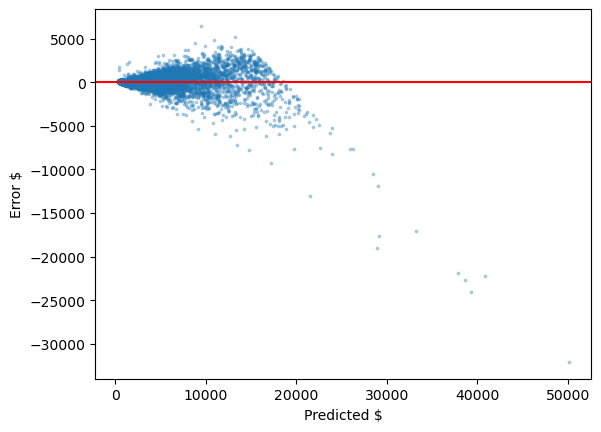

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred_log = model.predict(X_test)
pred = np.exp(pred_log)
actual = np.exp(y_test)

print("MAE  : $", mean_absolute_error(actual, pred))
print("RMSE : $", mean_squared_error(actual, pred) ** 0.5)
print("R²   :", r2_score(actual, pred))
print("R² (log scale):", r2_score(y_test, pred_log))

# Residual plot
plt.scatter(pred, actual - pred, s=3, alpha=.3)
plt.axhline(0, color="r"); plt.xlabel("Predicted $"); plt.ylabel("Error $"); plt.show()

In [8]:
coefs = pd.Series(model.named_steps["lr"].coef_, index=cats + nums)
print(coefs.sort_values(ascending=False))

log_carat    1.097736
clarity      0.123021
color        0.078007
cut          0.031985
dtype: float64
